<a href="https://colab.research.google.com/github/Logavarshhni23/DS_SAT_2/blob/main/DS_SAT_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import os
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# Find uploaded CSV files in Google Colab
DATA_DIR = "/content"

required_files = [
    "bookings.csv",
    "guests.csv",
    "hotels.csv",
    "channels.csv",
    "calendar.csv"
]

file_paths = {}

for filename in required_files:
    matches = glob.glob(f"{DATA_DIR}/**/{filename}", recursive=True)
    if not matches:
        raise FileNotFoundError(
            f"{filename} not found. Upload it to the Colab Files panel."
        )
    file_paths[filename] = matches[0]

# Load the five datasets
bookings = pd.read_csv(file_paths["bookings.csv"])
guests = pd.read_csv(file_paths["guests.csv"])
hotels = pd.read_csv(file_paths["hotels.csv"])
channels = pd.read_csv(file_paths["channels.csv"])
calendar = pd.read_csv(file_paths["calendar.csv"])

print("All five datasets loaded successfully!\n")

for name, df in [
    ("Bookings", bookings),
    ("Guests", guests),
    ("Hotels", hotels),
    ("Channels", channels),
    ("Calendar", calendar)
]:
    print(f"{name}: {df.shape[0]} rows, {df.shape[1]} columns")
    display(df.head(3))


All five datasets loaded successfully!

Bookings: 1822 rows, 9 columns


,booking_id,guest_id,hotel_id,channel_id,booking_date,stay_date,room_type,room_rate,booking_status
0,B000001,G00385,H002,CH06,2026-11-09,2027-02-17,DELUXE,4231,Checked-out
1,B000002,G00004,H001,CH03,2026-04-20,2026-06-19,Family Room,6886,Cancelled
2,B000003,G00116,H001,CH06,2026-03-06,2026-04-05,standard,2622,Confirmed


Guests: 650 rows, 4 columns


,guest_id,guest_type,origin,repeat_guest
0,G00001,Family,India,No
1,G00002,Leisure,United States,No
2,G00003,Couple,India,No


Hotels: 12 rows, 5 columns


,hotel_id,hotel_name,city,property_type,capacity
0,H001,StayNest Marina,Chennai,Business,120
1,H002,StayNest Central,Bengaluru,Business,150
2,H003,StayNest Hills,Ooty,Resort,80


Channels: 6 rows, 3 columns


,channel_id,booking_channel,campaign
0,CH01,Website,Direct
1,CH02,Mobile App,App Push
2,CH03,Online Travel Agent,OTA Promo


Calendar: 730 rows, 5 columns


,calendar_date,weekend,holiday,season,local_event
0,2025-01-01,No,Yes,Off-Peak,Yes
1,2025-01-02,No,No,Off-Peak,No
2,2025-01-03,No,No,Off-Peak,No


clean the datasets

In [ ]:

# Make independent copies
bookings = bookings.copy()
guests = guests.copy()
hotels = hotels.copy()
channels = channels.copy()
calendar = calendar.copy()

# Save original row count for reporting
original_rows = len(bookings)

# 1. Remove duplicate booking IDs
bookings = bookings.drop_duplicates(subset="booking_id", keep="first")

# 2. Convert date columns
bookings["booking_date"] = pd.to_datetime(
    bookings["booking_date"], errors="coerce"
)
bookings["stay_date"] = pd.to_datetime(
    bookings["stay_date"], errors="coerce"
)
calendar["calendar_date"] = pd.to_datetime(
    calendar["calendar_date"], errors="coerce"
)

# 3. Convert room rates to numeric
bookings["room_rate"] = pd.to_numeric(
    bookings["room_rate"], errors="coerce"
)

# Replace invalid or missing room rates with the median
bookings["room_rate"] = bookings["room_rate"].fillna(
    bookings["room_rate"].median()
)

# 4. Standardize room type labels
room_mapping = {
    "std": "Standard",
    "standard": "Standard",
    "dlx": "Deluxe",
    "deluxe": "Deluxe",
    "suite": "Suite",
    "family room": "Family",
    "family": "Family"
}

bookings["room_type"] = (
    bookings["room_type"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map(room_mapping)
    .fillna("Unknown")
)

# 5. Remove invalid dates and stays before booking date
bookings = bookings[
    bookings["booking_date"].notna()
    & bookings["stay_date"].notna()
    & (bookings["stay_date"] >= bookings["booking_date"])
].copy()

# 6. Identify and cap extreme room rates by room type
bookings["rate_outlier_flag"] = False

for room, indexes in bookings.groupby("room_type").groups.items():
    upper_limit = bookings.loc[indexes, "room_rate"].quantile(0.99)

    outlier_mask = bookings.loc[indexes, "room_rate"] > upper_limit
    bookings.loc[indexes, "rate_outlier_flag"] = outlier_mask

    bookings.loc[indexes, "room_rate"] = (
        bookings.loc[indexes, "room_rate"].clip(upper=upper_limit)
    )

# 7. Clean missing guest information
guests["origin"] = guests["origin"].fillna("Unknown")
guests["guest_type"] = guests["guest_type"].fillna("Unknown")
guests["repeat_guest"] = guests["repeat_guest"].fillna("Unknown")

# 8. Clean other categorical columns
for df in [hotels, channels, calendar]:
    for col in df.select_dtypes(include=["object", "string"]).columns:
        df[col] = df[col].fillna("Unknown").astype(str).str.strip()

# Remove duplicate lookup keys to prevent duplicate rows during merging
guests = guests.drop_duplicates(subset="guest_id")
hotels = hotels.drop_duplicates(subset="hotel_id")
channels = channels.drop_duplicates(subset="channel_id")
calendar = calendar.drop_duplicates(subset="calendar_date")

# Check cleaned data
print("CLEANING SUMMARY")
print("----------------")
print("Original bookings:", original_rows)
print("Bookings after cleaning:", len(bookings))
print("Duplicate booking IDs removed:", original_rows - len(bookings))
print("Missing values in bookings:\n")
display(bookings.isnull().sum().to_frame("Missing Values"))

print("\nStandardized room types:")
print(bookings["room_type"].value_counts())


CLEANING SUMMARY
----------------
Original bookings: 1822
Bookings after cleaning: 1778
Duplicate booking IDs removed: 44
Missing values in bookings:



,Missing Values
booking_id,0
guest_id,0
hotel_id,0
channel_id,0
booking_date,0
stay_date,0
room_type,0
room_rate,0
booking_status,0
rate_outlier_flag,0



Standardized room types:
room_type
Family      469
Deluxe      445
Standard    437
Suite       427
Name: count, dtype: int64


In [ ]:

# Calculate booking features
bookings["lead_time_days"] = (
    bookings["stay_date"] - bookings["booking_date"]
).dt.days

bookings["stay_month"] = bookings["stay_date"].dt.month
bookings["stay_year"] = bookings["stay_date"].dt.year
bookings["stay_day_of_week"] = bookings["stay_date"].dt.dayofweek
bookings["booking_month"] = bookings["booking_date"].dt.month
bookings["booking_year"] = bookings["booking_date"].dt.year
bookings["booking_day_of_week"] = bookings["booking_date"].dt.dayofweek

bookings["weekend_stay"] = np.where(
    bookings["stay_day_of_week"] >= 5, "Yes", "No"
)

# Merge bookings with guest details
master = bookings.merge(
    guests, on="guest_id", how="left", validate="many_to_one"
)

# Merge hotel details
master = master.merge(
    hotels, on="hotel_id", how="left", validate="many_to_one"
)

# Merge booking channel details
master = master.merge(
    channels, on="channel_id", how="left", validate="many_to_one"
)

# Merge calendar details using the intended stay date
master = master.merge(
    calendar,
    left_on="stay_date",
    right_on="calendar_date",
    how="left",
    validate="many_to_one"
)

# Fill calendar gaps, for example stay dates outside the calendar range
calendar_columns = ["weekend", "holiday", "season", "local_event"]

for col in calendar_columns:
    if col in master.columns:
        master[col] = master[col].fillna("Unknown")

# Create binary target: 1 = cancelled, 0 = not cancelled
master["is_cancelled"] = (
    master["booking_status"]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("cancelled")
    .astype(int)
)

print("MASTER DATASET CREATED")
print("Shape:", master.shape)
display(master.head())

print("\nBooking status distribution:")
display(master["booking_status"].value_counts().to_frame("Bookings"))

print("\nCancellation rate:")
print(f"{master['is_cancelled'].mean() * 100:.2f}%")

# Save cleaned and combined dataset
master.to_csv("/content/cleaned_bookings.csv", index=False)
print("\nSaved: /content/cleaned_bookings.csv")


MASTER DATASET CREATED
Shape: (1778, 33)


,booking_id,guest_id,hotel_id,channel_id,booking_date,stay_date,room_type,room_rate,booking_status,rate_outlier_flag,...,property_type,capacity,booking_channel,campaign,calendar_date,weekend,holiday,season,local_event,is_cancelled
0,B000001,G00385,H002,CH06,2026-11-09,2027-02-17,Deluxe,4231.0,Checked-out,False,...,Business,150,Call Center,Retention,NaT,Unknown,Unknown,Unknown,Unknown,0
1,B000002,G00004,H001,CH03,2026-04-20,2026-06-19,Family,6886.0,Cancelled,False,...,Business,120,Online Travel Agent,OTA Promo,2026-06-19,No,No,Shoulder,No,1
2,B000003,G00116,H001,CH06,2026-03-06,2026-04-05,Standard,2622.0,Confirmed,False,...,Business,120,Call Center,Retention,2026-04-05,Yes,No,Peak,No,0
3,B000004,G00050,H004,CH06,2025-02-15,2025-03-01,Deluxe,3731.0,Confirmed,False,...,Resort,75,Call Center,Retention,2025-03-01,Yes,No,Shoulder,No,0
4,B000005,G00590,H006,CH05,2026-09-05,2026-11-04,Suite,11908.0,Checked-out,False,...,Resort,100,Corporate,Corporate Rate,2026-11-04,No,No,Off-Peak,No,0



Booking status distribution:


,Bookings
booking_status,
Checked-out,969
Confirmed,418
Cancelled,300
No-show,91



Cancellation rate:
16.87%

Saved: /content/cleaned_bookings.csv


EDA

Cancellation rate by booking channel (%)


,Cancellation Rate (%)
booking_channel,
Online Travel Agent,33.33
Travel Agent,15.33
Mobile App,13.84
Corporate,13.57
Call Center,13.40
Website,12.29


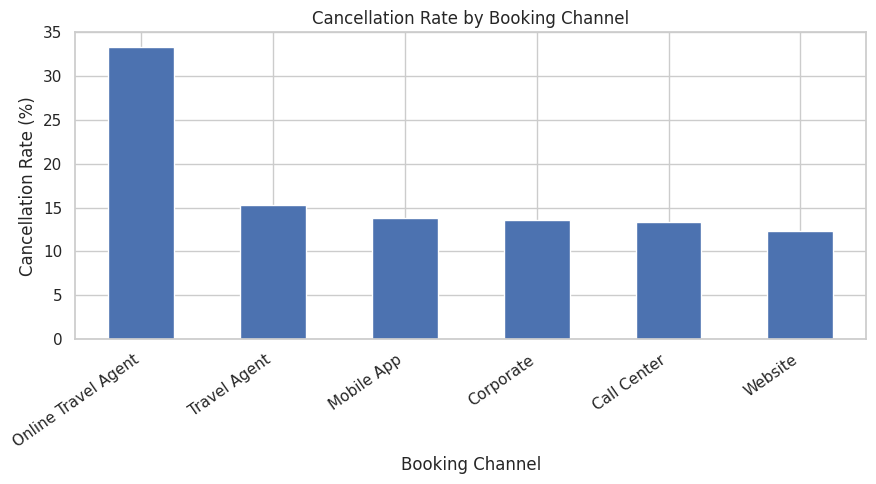

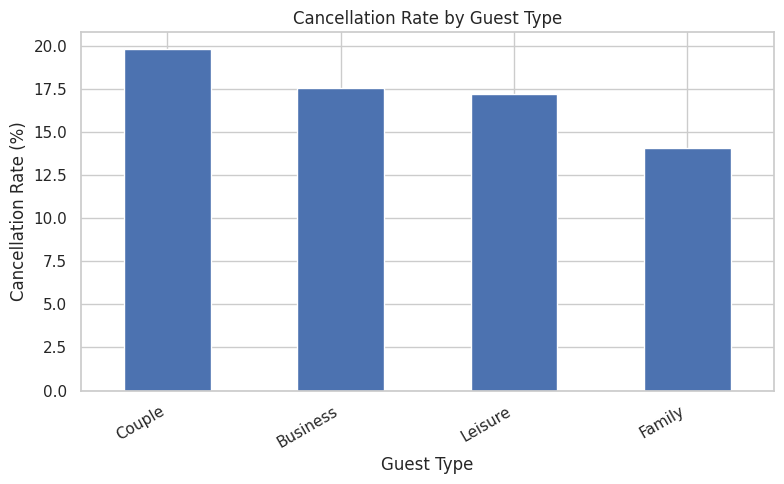

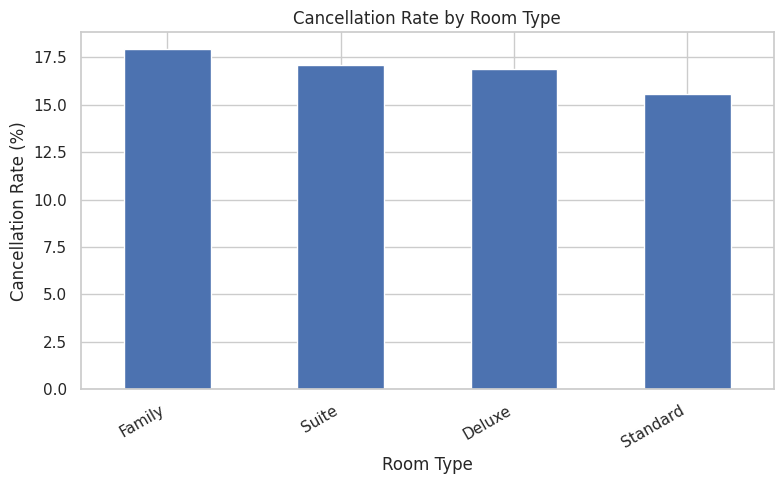

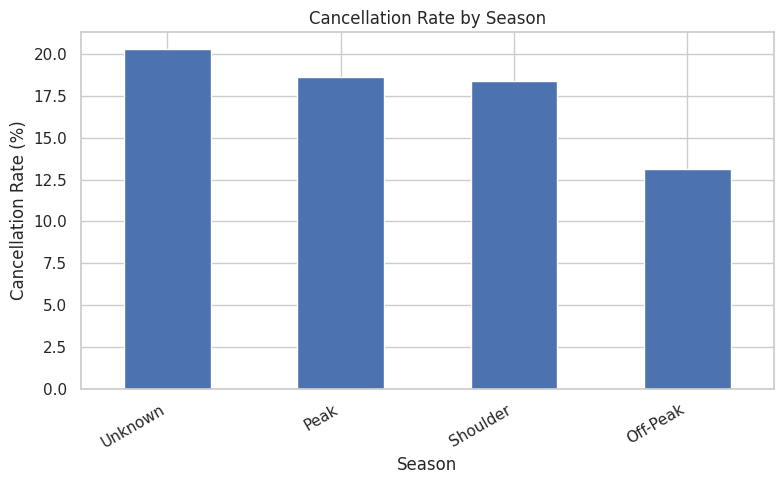

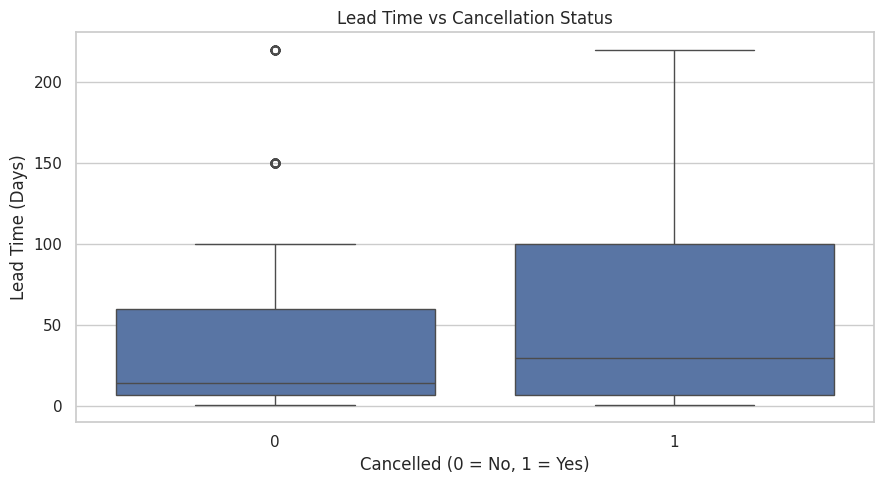

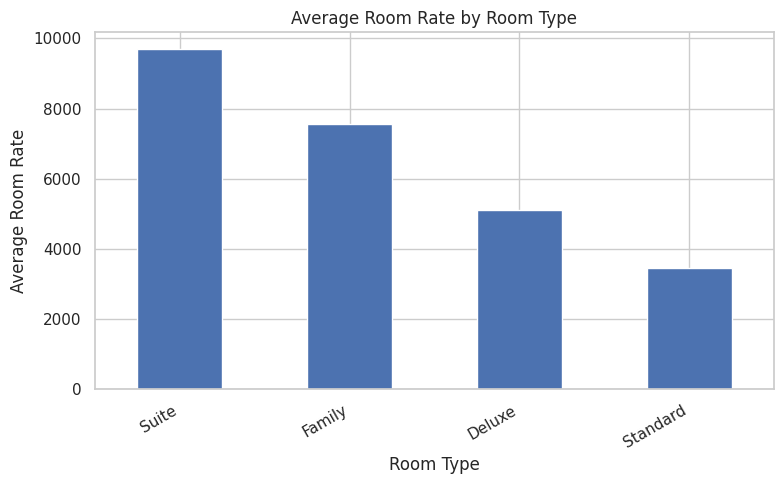

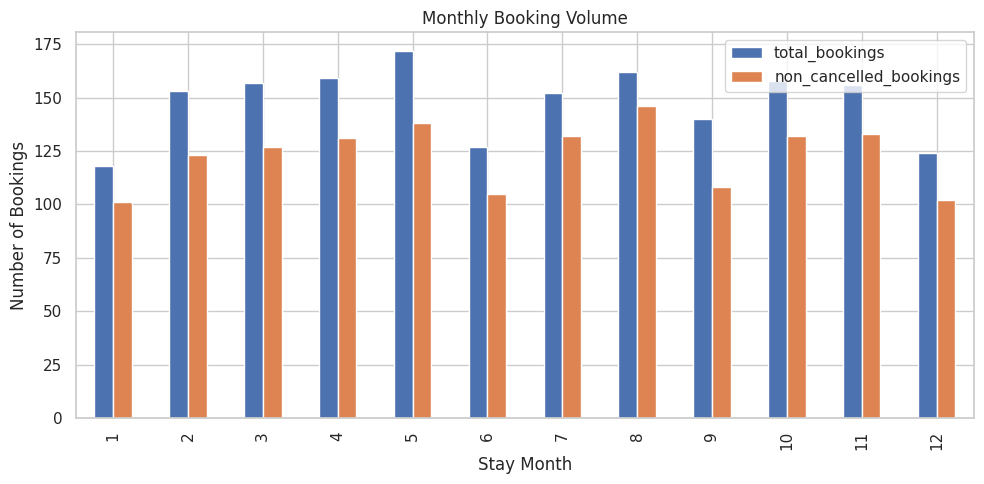

Monthly booking summary:


,total_bookings,cancelled_bookings,non_cancelled_bookings
stay_month,,,
1,118,17,101
2,153,30,123
3,157,30,127
4,159,28,131
5,172,34,138
6,127,22,105
7,152,20,132
8,162,16,146
9,140,32,108


In [ ]:

# 1. Cancellation rate by booking channel
channel_analysis = (
    master.groupby("booking_channel", observed=True)["is_cancelled"]
    .mean().mul(100).sort_values(ascending=False)
)

print("Cancellation rate by booking channel (%)")
display(channel_analysis.round(2).to_frame("Cancellation Rate (%)"))

channel_analysis.plot(kind="bar", figsize=(9, 5))
plt.title("Cancellation Rate by Booking Channel")
plt.xlabel("Booking Channel")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


# 2. Cancellation rate by guest type
guest_analysis = (
    master.groupby("guest_type", observed=True)["is_cancelled"]
    .mean().mul(100).sort_values(ascending=False)
)

guest_analysis.plot(kind="bar", figsize=(8, 5))
plt.title("Cancellation Rate by Guest Type")
plt.xlabel("Guest Type")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


# 3. Cancellation rate by room type
room_analysis = (
    master.groupby("room_type", observed=True)["is_cancelled"]
    .mean().mul(100).sort_values(ascending=False)
)

room_analysis.plot(kind="bar", figsize=(8, 5))
plt.title("Cancellation Rate by Room Type")
plt.xlabel("Room Type")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


# 4. Cancellation rate by season
season_analysis = (
    master.groupby("season", observed=True)["is_cancelled"]
    .mean().mul(100).sort_values(ascending=False)
)

season_analysis.plot(kind="bar", figsize=(8, 5))
plt.title("Cancellation Rate by Season")
plt.xlabel("Season")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


# 5. Relationship between lead time and cancellation
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=master,
    x="is_cancelled",
    y="lead_time_days"
)
plt.title("Lead Time vs Cancellation Status")
plt.xlabel("Cancelled (0 = No, 1 = Yes)")
plt.ylabel("Lead Time (Days)")
plt.tight_layout()
plt.show()


# 6. Average room rate by room type
rate_analysis = master.groupby("room_type")["room_rate"].mean().sort_values(
    ascending=False
)

rate_analysis.plot(kind="bar", figsize=(8, 5))
plt.title("Average Room Rate by Room Type")
plt.xlabel("Room Type")
plt.ylabel("Average Room Rate")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


# 7. Monthly booking volume and non-cancelled booking volume
monthly = master.groupby("stay_month").agg(
    total_bookings=("booking_id", "count"),
    cancelled_bookings=("is_cancelled", "sum")
)
monthly["non_cancelled_bookings"] = (
    monthly["total_bookings"] - monthly["cancelled_bookings"]
)

monthly[["total_bookings", "non_cancelled_bookings"]].plot(
    kind="bar", figsize=(10, 5)
)
plt.title("Monthly Booking Volume")
plt.xlabel("Stay Month")
plt.ylabel("Number of Bookings")
plt.tight_layout()
plt.show()

print("Monthly booking summary:")
display(monthly)


Model Training

MODEL EVALUATION
----------------
Accuracy : 0.806
Precision: 0.345
Recall   : 0.167
F1 Score : 0.225
ROC-AUC  : 0.613

Classification Report:
               precision    recall  f1-score   support

Not Cancelled       0.85      0.94      0.89       296
    Cancelled       0.34      0.17      0.22        60

     accuracy                           0.81       356
    macro avg       0.60      0.55      0.56       356
 weighted avg       0.76      0.81      0.78       356



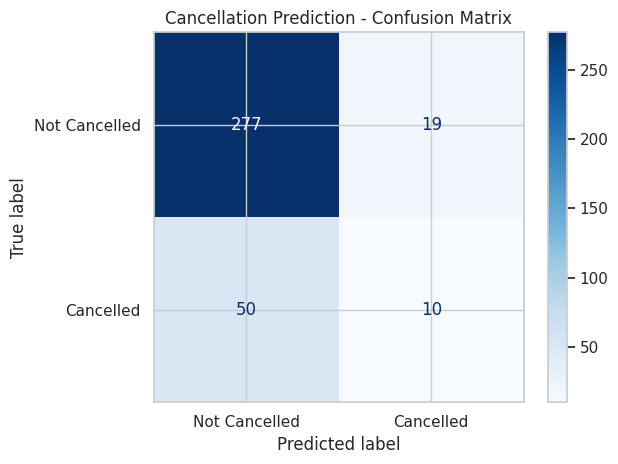

In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)

# Numeric and categorical features available for prediction
numeric_features = [
    "room_rate",
    "lead_time_days",
    "stay_month",
    "stay_year",
    "stay_day_of_week",
    "booking_month",
    "booking_year",
    "booking_day_of_week",
    "capacity"
]

categorical_features = [
    "room_type",
    "weekend_stay",
    "guest_type",
    "origin",
    "repeat_guest",
    "city",
    "property_type",
    "booking_channel",
    "campaign",
    "weekend",
    "holiday",
    "season",
    "local_event"
]

# Keep only columns present in the merged dataset
numeric_features = [
    c for c in numeric_features if c in master.columns
]
categorical_features = [
    c for c in categorical_features if c in master.columns
]

feature_columns = numeric_features + categorical_features

# Exclude booking status and all target-derived/unique identifier columns
X = master[feature_columns].copy()
y = master["is_cancelled"].copy()

# Ensure categorical columns are consistently handled
for col in categorical_features:
    X[col] = X[col].fillna("Unknown").astype(str)

for col in numeric_features:
    X[col] = pd.to_numeric(X[col], errors="coerce")

# Stratification keeps the cancellation proportion similar in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Prepare numeric and categorical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Create the model pipeline
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=3,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)
y_probability = model.predict_proba(X_test)[:, 1]

# Evaluate performance
print("MODEL EVALUATION")
print("----------------")
print(f"Accuracy : {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.3f}")
print(f"Recall   : {recall_score(y_test, y_pred, zero_division=0):.3f}")
print(f"F1 Score : {f1_score(y_test, y_pred, zero_division=0):.3f}")

if y_test.nunique() == 2:
    print(f"ROC-AUC  : {roc_auc_score(y_test, y_probability):.3f}")

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Not Cancelled", "Cancelled"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Not Cancelled", "Cancelled"],
    cmap="Blues"
)
plt.title("Cancellation Prediction - Confusion Matrix")
plt.tight_layout()
plt.show()


Finding important features

TOP 15 IMPORTANT FEATURES


,Feature,Importance
1,lead_time_days,0.1264
0,room_rate,0.0913
5,booking_month,0.0541
2,stay_month,0.0480
8,capacity,0.0476
7,booking_day_of_week,0.0470
4,stay_day_of_week,0.0421
53,campaign_OTA Promo,0.0370
47,booking_channel_Online Travel Agent,0.0308
26,repeat_guest_No,0.0202


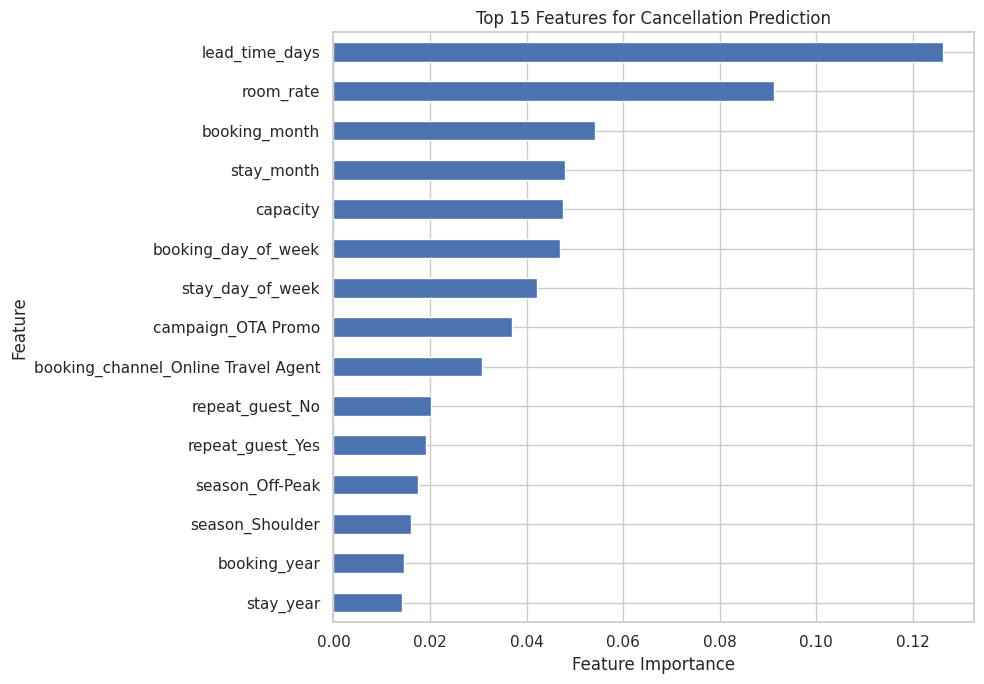


BUSINESS INSIGHTS
-----------------
Overall cancellation rate: 16.87%

Highest cancellation-rate booking channels:


,Cancellation Rate (%)
booking_channel,
Online Travel Agent,33.33
Travel Agent,15.33
Mobile App,13.84



Highest cancellation-rate guest types:


,Cancellation Rate (%)
guest_type,
Couple,19.78
Business,17.56
Leisure,17.17



Highest cancellation-rate room types:


,Cancellation Rate (%)
room_type,
Family,17.91
Suite,17.10
Deluxe,16.85



Cancellation rate by lead-time group:


,Cancellation Rate (%)
lead_time_group,
0–7 days,13.81
8–30 days,11.78
31–90 days,12.27
91–180 days,36.40
181+ days,31.48



Files saved:
1. cleaned_bookings.csv
2. feature_importance.csv
3. monthly_booking_analysis.csv


In [ ]:

# Retrieve feature names after preprocessing
fitted_preprocessor = model.named_steps["preprocessor"]
fitted_classifier = model.named_steps["classifier"]

feature_names = fitted_preprocessor.get_feature_names_out()
importances = fitted_classifier.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

# Clean up feature names for display
importance_df["Feature"] = (
    importance_df["Feature"]
    .str.replace("num__", "", regex=False)
    .str.replace("cat__", "", regex=False)
)

print("TOP 15 IMPORTANT FEATURES")
display(importance_df.head(15).round(4))

importance_df.head(15).sort_values("Importance").plot(
    kind="barh",
    x="Feature",
    y="Importance",
    figsize=(10, 7),
    legend=False
)
plt.title("Top 15 Features for Cancellation Prediction")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


# Business summaries from the cleaned data
print("\nBUSINESS INSIGHTS")
print("-----------------")

print(
    f"Overall cancellation rate: "
    f"{master['is_cancelled'].mean() * 100:.2f}%"
)

print("\nHighest cancellation-rate booking channels:")
display(channel_analysis.head(3).round(2).to_frame("Cancellation Rate (%)"))

print("\nHighest cancellation-rate guest types:")
display(guest_analysis.head(3).round(2).to_frame("Cancellation Rate (%)"))

print("\nHighest cancellation-rate room types:")
display(room_analysis.head(3).round(2).to_frame("Cancellation Rate (%)"))

print("\nCancellation rate by lead-time group:")
master["lead_time_group"] = pd.cut(
    master["lead_time_days"],
    bins=[-1, 7, 30, 90, 180, float("inf")],
    labels=["0–7 days", "8–30 days", "31–90 days",
            "91–180 days", "181+ days"]
)

lead_analysis = (
    master.groupby("lead_time_group", observed=True)["is_cancelled"]
    .mean().mul(100).round(2)
    .to_frame("Cancellation Rate (%)")
)
display(lead_analysis)

# Export key outputs
master.to_csv("/content/cleaned_bookings.csv", index=False)
importance_df.to_csv("/content/feature_importance.csv", index=False)
monthly.to_csv("/content/monthly_booking_analysis.csv")

print("\nFiles saved:")
print("1. cleaned_bookings.csv")
print("2. feature_importance.csv")
print("3. monthly_booking_analysis.csv")
